# Modelagem e Segmentação

**Dataset de entrada:** `data/processed/master.csv` (48.884 linhas x 14 colunas, sendo 2 coordenadas geograficas e 12 variaveis explicativas, ja limpo e sem nulos).

- Aplicar **K-Means**, **DBSCAN** e **HDBSCAN** sobre a `base padronizada`, 

- determinar o **K ideal** e os **hiperparametros** otimos de densidade, 

- diagnosticar a **estrutura topologica** aplicando Redução de Dimensionalidade com algorítmos `PCA (Linear)` e `UMAP (Não Linear)`, 

- Identificar os `Perfis comerciais` e sua **distribuição geoespacial**

---

### Sumario

| Secao | Topico |
| :--- | :--- |
| [1.0](#1.0) | Configuracao do Ambiente e Carregamento dos Dados |
| [2.0](#2.0) | Preparacao da Base de Perfilamento, Tratamento de Outliers e Padronizacao |
| [3.0](#3.0) | Modelagem Particional com K-Means e Diagnostico Topologico |
| [4.0](#4.0) | Modelagem Baseada em Densidade: DBSCAN vs. HDBSCAN |
| [5.0](#5.0) | Perfilamento Final e Mapeamento Geoespacial (HDBSCAN) |

___

## 1.0 Configuracao do Ambiente e Carregamento dos Dados

> **Parâmetros Globais de Reprodutibilidade (`configs.yaml`):**
> - **Base processada (`data.processed_dir` / `data.processed_filename`):** `data/processed/master.csv` (`48.884` registros válidos após remoção de `price <= 0`, com `14` colunas).
> - **Semente aleatória global (`modeling.random_state`):** `10` (aplicada no sorteio de pares, K-Means, amostragem de Silhouette, PCA e UMAP).
> - **Subamostragem de Silhouette (`modeling.subsample_silhouette`):** `10.000` pontos (reduz o custo quadrático $O(n^2)$ de ~2,39 bilhões de pares para 100 milhões, mantendo precisão estatística).


In [1]:
import os
import sys
import warnings
from pathlib import Path
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.compose import ColumnTransformer
import hdbscan
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import umap
import plotly.express as px
import plotly.graph_objects as go
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Point

sys.path.append(os.path.abspath(".."))
%load_ext autoreload
%autoreload 2

from src.config import carregar_configs
from src.plot_figs import (
    plot_elbow_comparativo,
    plot_metricas_validacao,
    plot_distribuicao_clusters,
    plot_clusters_2d_plotly,
    plot_metricas_dbscan,
    plot_metricas_hdbscan,
    plot_violino_perfis_hdbscan,
    plot_mapa_clusters_nyc,
)
from src.modeling import (
    avaliar_grade_dbscan,
    avaliar_grade_hdbscan,
)
from src.profiling import gerar_perfil_clusters

cfg = carregar_configs()
warnings.filterwarnings("ignore")


In [2]:
# Carregamento do dataset processado via configs.yaml:
# - processed_dir: "data/processed"
# - processed_filename: "master.csv"
nome_arquivo = cfg["data"]["processed_filename"]  # "master.csv"
DIR_ATUAL = os.getcwd()
DIR_ARQ = os.path.join(DIR_ATUAL, "..", cfg["data"]["processed_dir"], nome_arquivo)

X = pd.read_csv(DIR_ARQ)
display(X.head(10))
X.info()


,latitude,longitude,room_type,availability_365,price_log,reviews_per_month_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square_log,custo_estadia_log,volume_oferta_dias_anfitriao_log,meses_ativo_log
0,40.64749,-73.97237,1,365,5.010635,0.190620,1,0,0,0,2.590609,5.010635,7.692113,3.780933
1,40.75362,-73.98377,2,355,5.420535,0.322083,0,1,0,0,0.411027,5.420535,6.566672,4.782653
2,40.80902,-73.94190,1,365,5.017280,0.000000,0,1,0,0,2.048627,6.111467,5.902633,0.000000
3,40.68514,-73.95976,2,194,4.499810,1.729884,1,0,0,0,2.239329,4.499810,5.273000,4.080747
4,40.79851,-73.94399,2,0,4.394449,0.095310,0,1,0,0,1.902331,6.685861,0.000000,4.510850
5,40.74767,-73.97500,2,129,5.303305,0.463734,0,1,0,0,0.895967,6.398595,4.867534,4.839638
6,40.68688,-73.95596,1,0,4.110874,0.336472,1,0,0,0,2.229019,7.901377,0.000000,4.816239
7,40.76489,-73.98493,1,220,4.382027,1.497388,0,1,0,0,0.569643,5.068904,5.398163,4.827668
8,40.80178,-73.96723,1,0,4.382027,0.688135,0,1,0,0,1.809171,5.068904,0.000000,4.789089
9,40.71344,-73.99037,2,188,5.017280,0.845868,0,1,0,0,1.787050,5.017280,6.624065,4.798272


<class 'pandas.DataFrame'>
RangeIndex: 48884 entries, 0 to 48883
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           48884 non-null  float64
 1   longitude                          48884 non-null  float64
 2   room_type                          48884 non-null  int64  
 3   availability_365                   48884 non-null  int64  
 4   price_log                          48884 non-null  float64
 5   reviews_per_month_log              48884 non-null  float64
 6   neighbourhood_group_Brooklyn       48884 non-null  int64  
 7   neighbourhood_group_Manhattan      48884 non-null  int64  
 8   neighbourhood_group_Queens         48884 non-null  int64  
 9   neighbourhood_group_Staten Island  48884 non-null  int64  
 10  distancia_Times_Square_log         48884 non-null  float64
 11  custo_estadia_log                  48884 non-null  float64
 12  v

>
> Veja que para a futura **modelagem dos dados**, devemos: 
> 
> - Isolar as `Features Geográficas` 
>
> - Remover Outliers via **Clipping (1% de cada extremidade)**
>
> - **Padronizar** os dados para evitar distorções 

___

## 2.0 Preparacao da Base de Perfilamento, Tratamento de Outliers e Padronizacao

As transformações desta etapa seguem estritamente as listas e limites declarados em `configs.yaml` (`preprocessing`):

1. **`X_analise` (Reversão para Escala Real via `np.expm1` — `log_revert_cols`):**
   - Colunas revertidas (6): `price_log`, `reviews_per_month_log`, `distancia_Times_Square_log`, `custo_estadia_log`, `volume_oferta_dias_anfitriao_log` e `meses_ativo_log`.
   - *Consideração:* Enquanto os algoritmos treinam em escala logarítmica + padronizada (`X_tratado`), o perfilamento de negócio exige valores interpretáveis em dólares (US$), quilômetros, dias e meses (`X_analise`).

2. **`X_geo` vs. `X_modelo` (Isolamento Espacial — `geo_cols`):**
   - Colunas isoladas em `X_geo` (2): `latitude` e `longitude`.
   - *Consideração:* As coordenadas brutas são reservadas para plotagem cartográfica (GeoPandas). Se incluídas diretamente no treino junto às dummies de distrito e distância à Times Square, criariam redundância espacial e forçariam cortes puramente geográficos.

3. **Divisão entre Numéricas Contínuas (7) e Categóricas/Ordinais (5) em `X_modelo`:**
   - **Numéricas contínuas (`numerical_model_cols` — 7 colunas):** `availability_365`, `price_log`, `reviews_per_month_log`, `distancia_Times_Square_log`, `custo_estadia_log`, `volume_oferta_dias_anfitriao_log`, `meses_ativo_log`.
   - **Categóricas/Ordinais mantidas sem escalonamento (`passthrough` — 5 colunas):** `room_type` (`0`, `1`, `2`) e as 4 dummies `neighbourhood_group_Brooklyn`, `neighbourhood_group_Manhattan`, `neighbourhood_group_Queens`, `neighbourhood_group_Staten Island`.

4. **Clipping de Cauda (`clipping`) + Escalonamento Robusto (`RobustScaler`):**
   - **Limites escolhidos:** `lower_quantile = 0.01` (percentil 1%) e `upper_quantile = 0.99` (percentil 99%), aplicados **exclusivamente nas 7 variáveis numéricas contínuas**.
   - *Consideração:* Mesmo após o `log1p`, caudas extremas (ex.: estadias mínimas de 1.000 dias ou diárias de US$ 10.000) distorcem centroides. O *clipping* em `[1%, 99%]` apara esses extremos sem descartar linhas da base, e o `RobustScaler` (centrado na mediana e escalonado pelo IQR) garante resistência residual a outliers sem deformar as variáveis binárias (0/1).


In [ ]:
# 1. Construção de X_analise: reverte as 6 colunas _log para escala original com np.expm1 (configs.yaml)
# log_revert_cols = [
#     "price_log", "reviews_per_month_log", "distancia_Times_Square_log",
#     "custo_estadia_log", "volume_oferta_dias_anfitriao_log", "meses_ativo_log"
# ]
X_analise = X.copy()

cols_log = cfg["preprocessing"]["log_revert_cols"]
for col in cols_log:
    nome_original = col.replace("_log", "")
    X_analise[nome_original] = np.expm1(X_analise[col])
    X_analise = X_analise.drop(columns=[col])

print("X_analise:\n")
X_analise.info()

# 2. Separação das coordenadas geográficas: geo_cols = ["latitude", "longitude"]

geo_cols = cfg["preprocessing"]["geo_cols"]
X_geo = X[geo_cols].copy()
X_modelo = X.drop(columns=geo_cols)  # Mantém as 12 features explicativas para clusterização

# 3. Definição das 7 colunas numéricas contínuas vs. 5 categóricas (1 ordinal + 4 dummies):
# numerical_model_cols = [
#     "availability_365", "price_log", "reviews_per_month_log",
#     "distancia_Times_Square_log", "custo_estadia_log",
#     "volume_oferta_dias_anfitriao_log", "meses_ativo_log"
# ]

cols_numericas = cfg["preprocessing"]["numerical_model_cols"]

# cols_categoricas = ["room_type", "neighbourhood_group_Brooklyn", "neighbourhood_group_Manhattan",
#                     "neighbourhood_group_Queens", "neighbourhood_group_Staten Island"]

cols_categoricas = [c for c in X_modelo.columns if c not in cols_numericas]

# 4. Clipping nos quantis 1% (0.01) e 99% (0.99) APENAS nas 7 variáveis numéricas contínuas

q_inf = cfg["preprocessing"]["clipping"]["lower_quantile"]  # 0.01 (1º percentil)
q_sup = cfg["preprocessing"]["clipping"]["upper_quantile"]  # 0.99 (99º percentil)
X_clipado = X_modelo.copy()
lim_inf = X_clipado[cols_numericas].quantile(q_inf)
lim_sup = X_clipado[cols_numericas].quantile(q_sup)
X_clipado[cols_numericas] = X_clipado[cols_numericas].clip(lower=lim_inf, upper=lim_sup, axis=1)

# 5. RobustScaler APENAS nas 7 numéricas contínuas; categóricas (ordinal e dummies) passam intactas ("passthrough")
preprocessor = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), cols_numericas),
        ("cat", "passthrough", cols_categoricas)
    ],
    verbose_feature_names_out=False
).set_output(transform="pandas")

# Alinha a ordem das colunas de X_tratado com X_modelo (12 colunas)
X_tratado = preprocessor.fit_transform(X_clipado)[X_modelo.columns]

print("\n X_tratado: \n")
display(X_tratado.head(10))


X_analise:

<class 'pandas.DataFrame'>
RangeIndex: 48884 entries, 0 to 48883
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           48884 non-null  float64
 1   longitude                          48884 non-null  float64
 2   room_type                          48884 non-null  int64  
 3   availability_365                   48884 non-null  int64  
 4   neighbourhood_group_Brooklyn       48884 non-null  int64  
 5   neighbourhood_group_Manhattan      48884 non-null  int64  
 6   neighbourhood_group_Queens         48884 non-null  int64  
 7   neighbourhood_group_Staten Island  48884 non-null  int64  
 8   price                              48884 non-null  float64
 9   reviews_per_month                  48884 non-null  float64
 10  distancia_Times_Square             48884 non-null  float64
 11  custo_estadia                      48884 non-null  fl

,room_type,availability_365,price_log,reviews_per_month_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square_log,custo_estadia_log,volume_oferta_dias_anfitriao_log,meses_ativo_log
0,1,1.409692,0.366389,-0.136688,1,0,0,0,0.766074,-0.412463,0.621053,0.379767
1,2,1.365639,0.810971,0.008005,0,1,0,0,-2.054382,-0.169714,0.426778,0.664188
2,1,1.409692,0.373596,-0.346491,0,1,0,0,0.063065,0.239466,0.312150,-1.018492
3,2,0.656388,-0.187659,1.557475,1,0,0,0,0.310426,-0.714982,0.203461,0.490643
4,2,-0.198238,-0.301934,-0.241589,0,1,0,0,-0.126696,0.579631,-0.706773,0.649703
5,2,0.370044,0.683822,0.163910,0,1,0,0,-1.432056,0.409508,0.133469,0.664188
6,1,-0.198238,-0.609503,0.023841,1,0,0,0,0.297053,1.299478,-0.706773,0.664188
7,1,0.770925,-0.315408,1.301583,0,1,0,0,-1.855334,-0.377955,0.225067,0.664188
8,1,-0.198238,-0.315408,0.410892,0,1,0,0,-0.247534,-0.377955,-0.706773,0.664188
9,2,0.629956,0.373596,0.584499,0,1,0,0,-0.276228,-0.408528,0.436685,0.664188


### 2.1 Teste de Distância antes ou Depois da Normalização ( Compensa mesmo fazer Scaler? )

>
> **Cenario A:** Encoding (One-Hot + Ordinal), sem escalonamento das numericas (`X_modelo`).
>
> **Cenario B:** Encoding + RobustScaler nas numericas, dummies e ordinais intactas via ColumnTransformer (`X_tratado`).
>
> Selecionamos **dois anuncios reais distintos da base**  e calculamos a distancia Euclidiana entre eles em ambos os cenarios. A tabela abaixo mostra a contribuicao quadratica **(x_j - y_j)^2 de cada feature** para a distancia total, evidenciando qual atributo domina cada cenario.
>
> $$d(x, y) = \sqrt{\sum_{j=1}^{d} (x_j - y_j)^2}$$

In [ ]:
# Experimento controlado: distância Euclidiana entre anúncios reais (configs.yaml)

# - random_state = 10 (garante sorteio idêntico dos pares de imóveis)

# - distance_experiment_n_obs = 10 (avalia 10 pares aleatórios sem escala vs. com RobustScaler)

seed = cfg["modeling"]["random_state"]              # 10
random.seed(seed)
np.random.seed(seed)

n_elementos = X_tratado.shape[0]
n_obs = cfg["modeling"]["distance_experiment_n_obs"]  # 10 pares

dists_antes, dists_depois = [], []
contribs_antes, contribs_depois = [], []
pares = []

for i in range(n_obs):
    idx_a = random.randint(0, n_elementos - 1)
    idx_b = random.randint(0, n_elementos - 1)
    while idx_b == idx_a:
        idx_b = random.randint(0, n_elementos - 1)
    pares.append((idx_a, idx_b))

    a_raw, b_raw = X_modelo.iloc[idx_a], X_modelo.iloc[idx_b]
    a_sca, b_sca = X_tratado.iloc[idx_a], X_tratado.iloc[idx_b]

    c_antes = ((a_raw - b_raw) ** 2).values
    c_depois = ((a_sca - b_sca) ** 2).values

    dists_antes.append(np.sqrt(c_antes.sum()))
    dists_depois.append(np.sqrt(c_depois.sum()))
    contribs_antes.append(c_antes)
    contribs_depois.append(c_depois)

contribs_antes = np.vstack(contribs_antes)
contribs_depois = np.vstack(contribs_depois)

mean_contrib_antes = contribs_antes.mean(axis=0)
mean_contrib_depois = contribs_depois.mean(axis=0)

tabela_dist = pd.DataFrame({
    "Feature": X_modelo.columns,
    "Contrib_Quad_media_antes (sem escala)": mean_contrib_antes.round(4),
    "Contrib_Quad_media_depois (RobustScaler)": mean_contrib_depois.round(4),
})

dist_media_antes = np.mean(dists_antes)
dist_media_depois = np.mean(dists_depois)
dist_std_antes = np.std(dists_antes)
dist_std_depois = np.std(dists_depois)

top_antes = tabela_dist.nlargest(5, "Contrib_Quad_media_antes (sem escala)")
top_depois = tabela_dist.nlargest(5, "Contrib_Quad_media_depois (RobustScaler)")

print(f"Distância Euclidiana — média em {n_obs} pares")
print(f"  Cenário A (sem escala):     {dist_media_antes:.4f}  ± {dist_std_antes:.4f}")
print(f"  Cenário B (RobustScaler):   {dist_media_depois:.4f}  ± {dist_std_depois:.4f}")

print("\nTop 5 features dominantes — Cenário A (sem escala):")
display(top_antes[["Feature", "Contrib_Quad_media_antes (sem escala)"]])

print("\nTop 5 features dominantes — Cenário B (RobustScaler):")
display(top_depois[["Feature", "Contrib_Quad_media_depois (RobustScaler)"]])

print("\nTabela completa — contribuição quadrática média por feature:")
display(tabela_dist)
print(f"\nPares sorteados (idx_a, idx_b): {pares}")


Distância Euclidiana — média em 10 pares
  Cenário A (sem escala):     163.0947  ± 111.1451
  Cenário B (RobustScaler):   2.8544  ± 0.4910

Top 5 features dominantes — Cenário A (sem escala):


,Feature,Contrib_Quad_media_antes (sem escala)
1,availability_365,38918.2000
10,volume_oferta_dias_anfitriao_log,19.1904
11,meses_ativo_log,7.2026
9,custo_estadia_log,4.6374
2,price_log,0.7813



Top 5 features dominantes — Cenário B (RobustScaler):


,Feature,Contrib_Quad_media_depois (RobustScaler)
9,custo_estadia_log,1.5872
11,meses_ativo_log,0.9851
2,price_log,0.9191
3,reviews_per_month_log,0.8469
8,distancia_Times_Square_log,0.8232



Tabela completa — contribuição quadrática média por feature:


,Feature,Contrib_Quad_media_antes (sem escala),Contrib_Quad_media_depois (RobustScaler)
0,room_type,0.5000,0.5000
1,availability_365,38918.2000,0.7553
2,price_log,0.7813,0.9191
3,reviews_per_month_log,0.6991,0.8469
4,neighbourhood_group_Brooklyn,0.3000,0.3000
5,neighbourhood_group_Manhattan,0.7000,0.7000
6,neighbourhood_group_Queens,0.4000,0.4000
7,neighbourhood_group_Staten Island,0.0000,0.0000
8,distancia_Times_Square_log,0.4893,0.8232
9,custo_estadia_log,4.6374,1.5872



Pares sorteados (idx_a, idx_b): [(37447, 2135), (28107, 31625), (37885, 972), (13506, 30315), (32197, 18187), (42825, 10500), (2254, 34122), (32118, 21480), (4986, 16383), (48860, 23668)]


___

## 3.0 Modelagem Particional com K-Means

### 3.1 Fundamentos Matematicos

K-Means e um algoritmo que separa um conjunto de `n` pontos em `k` grupos/clusters com pontos semelhantes entre si.

Cada grupo (cluster) possui um **centroide**, que e atribuido como o centro de cada cluster. Ele **nao necessariamente e um ponto real do dataset**.

#### Formula do centroide

$$
\mu_k = \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i
$$

#### Distancia Euclidiana

$$
d(x, \mu) = \sqrt{\sum_{j=1}^{d} (x_j - \mu_j)^2}
$$

Na pratica, o K-Means usa a **distancia euclidiana ao quadrado** (sem a raiz):

$$
\|x - \mu\|^2 = \sum_{j=1}^{d} (x_j - \mu_j)^2
$$
>
> Por isso, e extremamente importante **padronizar os dados de entrada**. Features com escalas diferentes dominariam o calculo da distancia.
>

### 3.2 Ciclo do Algoritmo

O algoritmo e iterativo e alterna entre atribuicao e recalculo dos centros:

**1) Inicializar centros aleatorios (Forgy / K-Means++)**

O metodo de Forgy sorteia `k` pontos reais do dataset como centros iniciais. Uma alternativa melhor e o **K-Means++**, que escolhe centros espalhados proporcionalmente a **distancia ao quadrado ao centro mais proximo** ja escolhido.

**2) Atribuir cada ponto ao centroide mais proximo**

$$
\text{cluster}(x_i) = \arg\min_{k=1,\dots,K} \|x_i - \mu_k\|^2
$$

**3) Recalcular os centroides**

$$
\mu_k \leftarrow \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i
$$

**4) Repetir ate convergir**

Repete-se os passos 2 e 3 ate que as atribuicoes nao mudem mais, os centroides se movam menos que uma tolerancia `epsilon`, ou atinja-se um numero maximo de iteracoes.

> Cada passo nunca aumenta a inercia, entao o algoritmo converge — mas para um **minimo local**. Por isso e comum rodar varias inicializacoes (`n_init`) e ficar com a de menor inercia.

### 3.3 Metricas de Avaliacao

Como nao ha rotulos verdadeiros, avaliamos a qualidade geometrica da particao: **coesao** (pontos perto do seu centroide) e **separacao** (clusters longe uns dos outros).

#### Inertia (WCSS — Within-Cluster Sum of Squares)

$$
\text{Inertia} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2
$$

- **Menor e melhor** (e o objetivo que o K-Means minimiza).
- **Nao serve para comparar `k` diferentes**, pois sempre diminui quando `k` aumenta.
- Uso classico: **metodo do cotovelo (elbow)** — plotar inercia vs. `k` e procurar o "joelho" da curva.

#### Silhouette

Para cada ponto `i`:
- `a(i)` = distancia media aos outros pontos do **mesmo cluster** (coesao)
- `b(i)` = distancia media aos pontos do **cluster vizinho mais proximo** (separacao)

$$
s(i) = \frac{b(i) - a(i)}{\max(a(i),\, b(i))} \in [-1, 1]
$$

- **Maior e melhor** (perto de +1 = ponto bem dentro do seu cluster).
- Custo `O(n^2)` — caro para `n` grande.

#### Davies-Bouldin

$$
\text{DB} = \frac{1}{K} \sum_{i=1}^{K} \max_{j \neq i} \frac{s_i + s_j}{d(\mu_i,\, \mu_j)}
$$

- **Menor e melhor** (0 e o ideal).

#### Calinski-Harabasz

$$
\text{CH} = \frac{\operatorname{tr}(B_K)/(K-1)}{\operatorname{tr}(W_K)/(n-K)}
$$

- **Maior e melhor** (clusters compactos e bem separados).
- Custo `O(n)`, relativamente barato.

| Metrica | O que mede | Direcao | Compara `k`? | Custo |
|---|---|---|---|---|
| **Inertia** | coesao interna (SSE) | menor melhor | nao | `O(nKd)` |
| **Silhouette** | coesao + separacao | maior melhor | sim | `O(n^2)` |
| **Davies-Bouldin** | dispersao / separacao | menor melhor | sim | `O(nKd + K^2d)` |
| **Calinski-Harabasz** | var. entre / var. interna | maior melhor | sim | `O(nKd)` |

### 3.4 Determinacao do K Ideal (Metodo Elbow e Metricas)

> **Parâmetros de Busca do K-Means (`configs.yaml` -> `modeling.kmeans`):**
> - **Curva de Inércia (Método Elbow):** `elbow_k_range = [1, 21]` (avalia $K$ de `1` a `20`), `elbow_n_init = 20` reinicializações com `k-means++`, `max_iter = 300` e `random_state = 10`.
> - **Métricas de Validação Geométrica (Silhouette, Davies-Bouldin e Calinski-Harabasz):** `metrics_k_range = [2, 11]` (avalia $K$ de `2` a `10`, pois métricas de separação exigem pelo menos 2 grupos), `n_init = 10`, `max_iter = 300`, `subsample_silhouette = 10000` e `random_state = 10`.


[figures] 02_kmeans_elbow.png salvo.


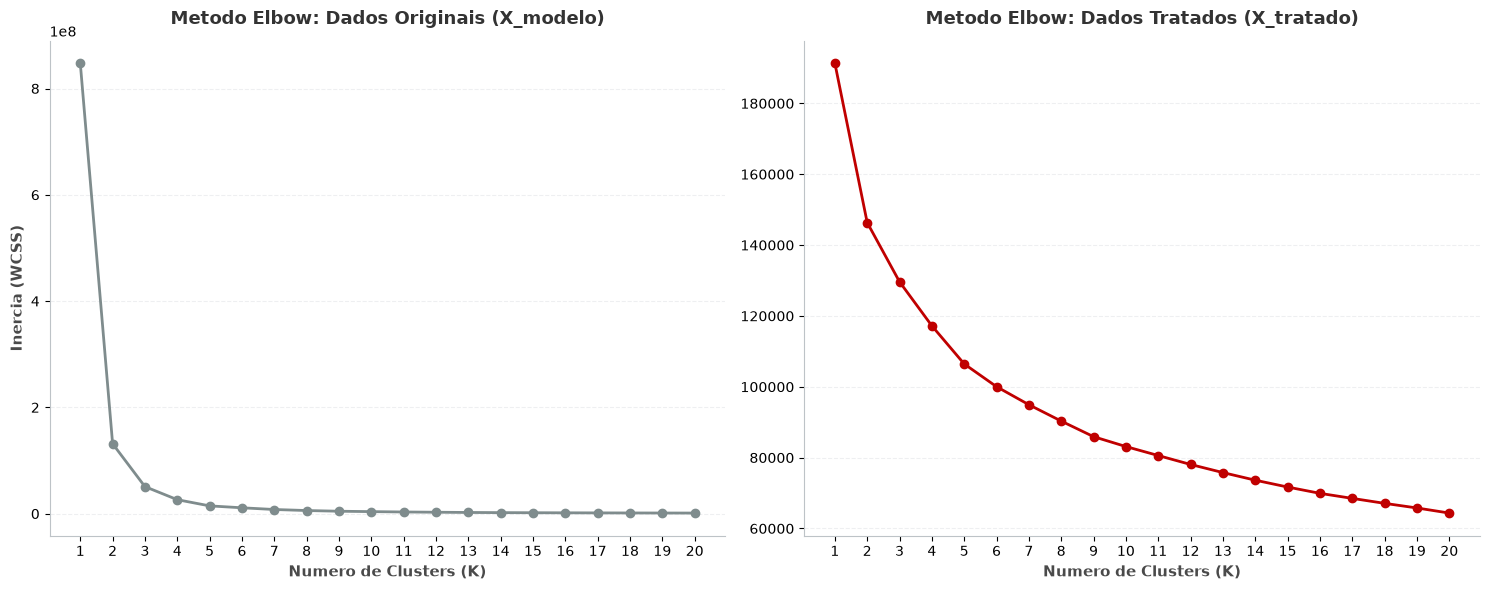

In [ ]:
# Método Elbow parametrizado via configs.yaml:

# - elbow_k_range: [1, 21] -> testa K de 1 até 20

# - elbow_n_init: 20       -> 20 inicializações K-Means++ por valor de K

# - max_iter: 300          -> limite máximo de iterações por execução

# - random_state: 10       -> semente de reprodutibilidade

km_cfg = cfg["modeling"]["kmeans"]
seed = cfg["modeling"]["random_state"]
k_valores = list(range(*km_cfg["elbow_k_range"]))
inercias_x = []
inercias_x_tratado = []

for k in k_valores:
    modelo_km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=km_cfg["elbow_n_init"],
        max_iter=km_cfg["max_iter"],
        random_state=seed,
    )
    modelo_km.fit(X_modelo)
    inercias_x.append(modelo_km.inertia_)

    modelo_km.fit(X_tratado)
    inercias_x_tratado.append(modelo_km.inertia_)

plot_elbow_comparativo(k_valores, inercias_x, inercias_x_tratado)



> Com os **dados originais sem tratamento**, a Inercia aparece na casa de `10^8`, muito alto,  e possui **grandes oscilacoes** como é possível verificar entre `K=1 e K=3`
>
> Para **X_tratado** (RobustScaler + Clipping), os dados decrescem de maneira bem mais uniforme, reduzindo a inercia associada para a casa do `10^5`
>
>  O **range de K entre 7 e 12 apresenta ponto de inflexao visivel**, com `menor reducao marginal e maior estabilidade`,mas devemos buscar mais métricas pra encontrar o melhor K

,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Tamanho_dos_Clusters
0,2,146351.50,0.22,1.73,15029.11,"{0: 19826, 1: 29058}"
1,3,129635.44,0.17,1.89,11634.86,"{0: 19562, 1: 16367, 2: 12955}"
2,4,117277.63,0.16,1.87,10290.61,"{0: 14631, 1: 13903, 2: 11974, 3: 8376}"
3,5,106445.90,0.17,1.72,9746.61,"{0: 9936, 1: 6368, 2: 11574, 3: 10098, 4: 10908}"
4,6,100025.75,0.17,1.70,8925.02,"{0: 9936, 1: 5024, 2: 8729, 3: 5568, 4: 9909, ..."
5,7,94934.04,0.17,1.74,8273.17,"{0: 5163, 1: 9346, 2: 8716, 3: 6585, 4: 5337, ..."
6,8,90314.31,0.17,1.74,7811.04,"{0: 6574, 1: 4979, 2: 8477, 3: 8432, 4: 4696, ..."
7,9,85916.46,0.17,1.67,7497.09,"{0: 4953, 1: 6612, 2: 6810, 3: 4198, 4: 5483, ..."
8,10,83127.22,0.17,1.66,7069.74,"{0: 6606, 1: 4602, 2: 5095, 3: 5722, 4: 6648, ..."


[figures] 02_kmeans_metricas.png salvo.


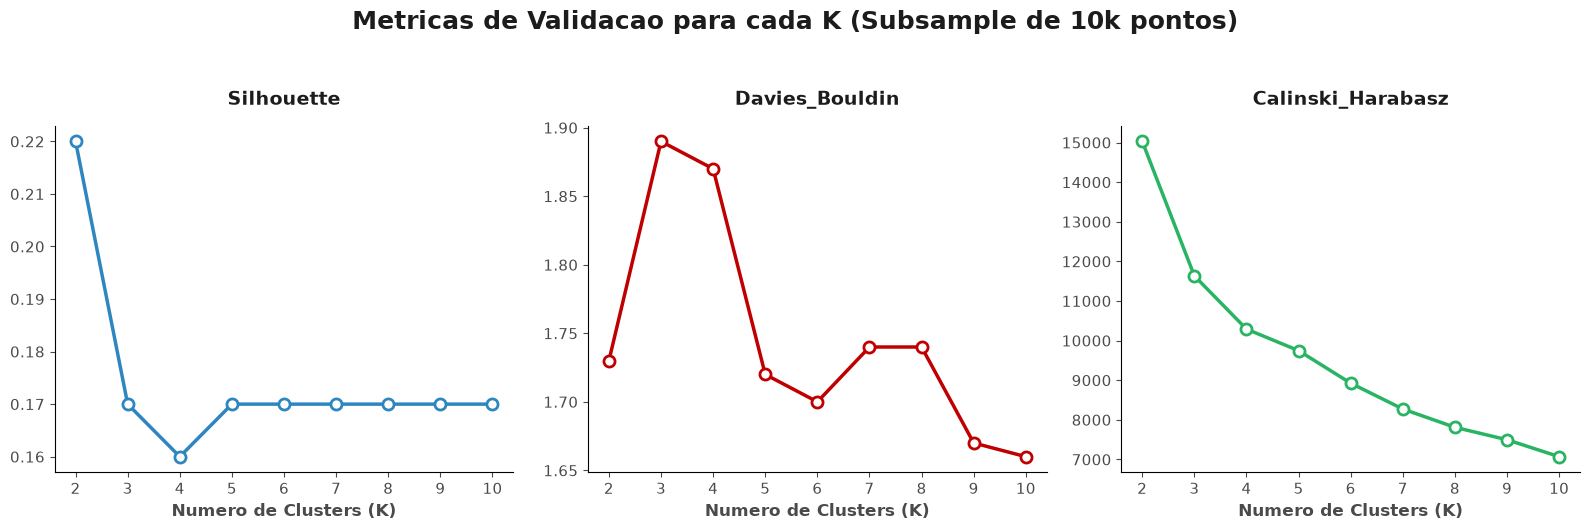

In [ ]:
# Métricas de validação para K-Means (configs.yaml):

# - metrics_k_range: [2, 11]    -> avalia K de 2 até 10

# - n_init: 10, max_iter: 300   -> parâmetros de convergência

# - subsample_silhouette: 10000 -> amostragem para cálculo rápido de Silhouette

# - random_state: 10

km_cfg = cfg["modeling"]["kmeans"]
seed = cfg["modeling"]["random_state"]
subsample = cfg["modeling"]["subsample_silhouette"]
k_valores = range(*km_cfg["metrics_k_range"])
resultados_metricas = []

for k in k_valores:
    km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=km_cfg["n_init"],
        max_iter=km_cfg["max_iter"],
        random_state=seed,
    )
    labels = km.fit_predict(X_tratado)

    valores_unicos, contagens = np.unique(labels, return_counts=True)
    distribuicao_tamanhos = {int(c): int(q) for c, q in zip(valores_unicos, contagens)}

    resultados_metricas.append({
        "K": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(X_tratado, labels, sample_size=subsample, random_state=seed),
        "Davies_Bouldin": davies_bouldin_score(X_tratado, labels),
        "Calinski_Harabasz": calinski_harabasz_score(X_tratado, labels),
        "Tamanho_dos_Clusters": distribuicao_tamanhos,
    })

df_resultados = pd.DataFrame(resultados_metricas)
colunas_float = ["Inertia", "Silhouette", "Davies_Bouldin", "Calinski_Harabasz"]
df_resultados[colunas_float] = df_resultados[colunas_float].round(2)
display(df_resultados)

plot_metricas_validacao(df_resultados)


In [ ]:
# Exportação das métricas K-Means (configs.yaml)

DIR_METRICS = os.path.join("..", cfg["artifacts"]["metrics_dir"])
os.makedirs(DIR_METRICS, exist_ok=True)
df_resultados.to_csv(os.path.join(DIR_METRICS, "kmeans_metrics.csv"), index=False)
print(f"K-Means metrics exportados -> {DIR_METRICS}/kmeans_metrics.csv")

K-Means metrics exportados -> reports/metrics/kmeans_metrics.csv


> * **Observacao Principal:** A partir de **K=5**, o **Silhouette Score** estabiliza-se em **0.17**, enquanto o **Calinski-Harabasz** mantem queda gradual e controlada (de 9.746,61 em K=5 para 7.069,74 em K=10).
>
> * **Comportamento do Davies-Bouldin e Equilibrio de Volume:** O Indice Davies-Bouldin oscila na faixa de **1.66 a 1.74** entre K=5 e K=10. Em **K=8** (`DB = 1.74`, `Inercia = 90.314,31`, `CH = 7.811,04`), observa-se uma inflexao consolidada da curva Elbow acompanhada de uma divisao de volume equilibrada (grupos entre ~4,7k e ~8,5k registros).
>
> * **Decisao:** Seleciona-se **K=8** como referencia particional para avaliar se cortes esfericos conseguem separar adequadamente os perfis operacionais e geograficos da base.

### 3.5 Ajuste Final (K=8) e Distribuicao de Volume

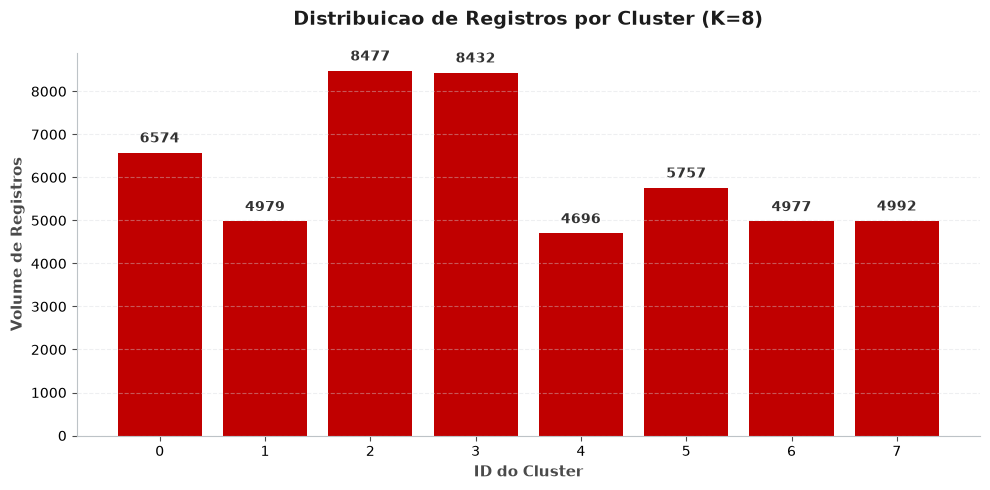

In [ ]:
# Ajuste do modelo final K-Means conforme escolha consolidada em configs.yaml:

# - best_k: 8 (ponto de inflexão da curva Elbow com equilíbrio entre DB=1.74, Silhouette=0.17 e volume)

# - n_init: 10, max_iter: 300, random_state: 10

km_cfg = cfg["modeling"]["kmeans"]
best_k = km_cfg["best_k"]          # 8 clusters
seed = cfg["modeling"]["random_state"]  # 10

km_final = KMeans(
    n_clusters=best_k,
    init="k-means++",
    n_init=km_cfg["n_init"],
    max_iter=km_cfg["max_iter"],
    random_state=seed,
)
labels_k8 = km_final.fit_predict(X_tratado)

plot_distribuicao_clusters(
    labels_k8,
    titulo=f"Distribuicao de Registros por Cluster (K={best_k})"
)


> - Os **8 clusters apresentam distribuicao parcialmente equilibrada**, com tamanhos variando entre aproximadamente `3k e 9k pontos`.
>
> A princípio, **numa análise inicial**, a `ausencia de clusters extremamente desbalanceados indica que o K-Means conseguiu segmentar a base de forma razoavel`.
>
> Nesse sentido, como estamos **trabalhando com clusterização** devemos analisar a como a `Red de Dimensionalidade` impacta na segmentação e interpretabilidade dos pontos.

### 3.6 Reducao de Dimensionalidade e Diagnostico Topologico do K-Means (PCA e UMAP)

> **Parâmetros de Projeção (`configs.yaml` -> `modeling.pca` e `modeling.umap`):**
> - **PCA (Projeção Linear Ortogonal):** `n_components = 2`, `random_state = 10` — retém **50,83%** da variância total das 12 variáveis (`34,12%` na PC1 + `16,71%` na PC2).
> - **UMAP (Projeção Topológica Não-Linear):** `n_components = 2`, `n_neighbors = 30` (tamanho da vizinhança local para aproximar a variedade Riemanniana sem perder a estrutura global), `min_dist = 0.1` (controla o quão próximos os pontos podem ficar no espaço 2D) e `random_state = 10`.
> - A comparação entre `PCA` e `UMAP` permite diagnosticar visualmente se os cortes hiperesféricos do K-Means ($K=8$) respeitam a topologia natural dos imóveis.


In [ ]:
# Paleta e projeções PCA e UMAP parametrizadas via configs.yaml:

# - pca:  n_components = 2, random_state = 10

# - umap: n_components = 2, n_neighbors = 30, min_dist = 0.1, random_state = 10

CORES_CLUSTERS = {int(k): v for k, v in cfg["visualization"]["kmeans_colors"].items()}
seed = cfg["modeling"]["random_state"]  
pca_cfg = cfg["modeling"]["pca"]
umap_cfg = cfg["modeling"]["umap"]

# 1. PCA (2 componentes lineares)
pca = PCA(n_components=pca_cfg["n_components"], random_state=seed)
X_pca = pca.fit_transform(X_tratado)

var_explicada = pca.explained_variance_ratio_
print(f"Variancia explicada individual: {np.round(var_explicada * 100, 2)}%")
print(f"Variancia total mantida (2 comp.): {var_explicada.sum() * 100:.2f}%")

df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df_pca["Cluster"] = labels_k8

# 2. UMAP (2 componentes não-lineares: n_neighbors=30, min_dist=0.1)
redutor_umap = umap.UMAP(
    n_components=umap_cfg["n_components"],
    n_neighbors=umap_cfg["n_neighbors"],
    min_dist=umap_cfg["min_dist"],
    random_state=seed,
)
X_umap = redutor_umap.fit_transform(X_tratado)

df_umap = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
df_umap["Cluster"] = labels_k8


Variancia explicada individual: [34.12 16.71]%
Variancia total mantida (2 comp.): 50.83%


In [10]:
# Projecao 2D via PCA (componentes principais lineares)
plot_clusters_2d_plotly(
    df_pca, col_x='PC1', col_y='PC2',
    mapa_cores=CORES_CLUSTERS,
    titulo='Projecao 2D (PCA): Clusters do K-Means (K=8)'
)

>
> Com **50.83% da variancia retida em 2D** (`34.12%` na PC1 e `16.71%` na PC2), o **PCA mostra forte sobreposicao continua entre os clusters**, indicando que a estrutura dos dados nao e linearmente separavel por hiperplanos ortonormais.
>
> Nesse sentido, aplicamos a reducao nao-linear via **UMAP** para verificar se a geometria esferica imposta pelo K-Means respeita as variedades topologicas reais do dataset.

In [11]:
# Projecao 2D via UMAP (estrutura topologica nao-linear)
plot_clusters_2d_plotly(
    df_umap, col_x='UMAP1', col_y='UMAP2',
    mapa_cores=CORES_CLUSTERS,
    titulo='Projecao 2D (UMAP): Clusters do K-Means (K=8)'
)


> O **UMAP revela ilhas nao-lineares** as quais o K-Means, por `impor fronteiras esfericas`, corta **artificialmente ao meio**. 
>
> Varios clusters apresentam **intersecções sobrepostas** que `não correspondem a agrupamentos naturais esperados para grupos de imóveis.`
>
> Mesmo com um algoritmo de **redução nao-linear**, o K-Means `não conseguiu capturar a topologia real dos dados`. 
>
> As entre **fronteiras e geometrias dos agrupamentos sao mais complexas** e exigem algoritmos baseados em `densidade (DBSCAN/HDBSCAN)`, de modo a respeitar a **geometria e identificar ruídos**

### 3.7 Perfilamento Preliminar dos Clusters (K-Means)

In [ ]:
# Perfilamento em escala original (X_analise) usando as dummies configuradas em configs.yaml:

# bairros_dummies = [
#     "neighbourhood_group_Brooklyn",
#     "neighbourhood_group_Manhattan",
#     "neighbourhood_group_Queens",
#     "neighbourhood_group_Staten Island" ]
# 

bairros_dummies = cfg["preprocessing"]["bairros_dummies"]

X_analise["Cluster_KMeans"] = labels_k8
perfil_km, distritos_km = gerar_perfil_clusters(X_analise, "Cluster_KMeans", bairros_dummies)

display(perfil_km)
display(distritos_km)


,Tamanho_do_Cluster,Preco_Mediano,Preco_Q1,Preco_Q3,Disponibilidade_Mediana,Reviews_Mes_Mediana,Distancia_TS_km_Mediana,Custo_Estadia_Mediano,Meses_Ativos_Mediana,Volume_Oferta_Host,room_type_Moda,Perc_Base (%)
Cluster_KMeans,,,,,,,,,,,,
0,6574,135.0,100.0,185.75,0.0,0.16,8.19,475.0,18.52,0.0,2,13.45
1,4979,143.0,100.0,200.00,164.0,2.33,3.22,290.0,15.09,207.0,2,10.19
2,8477,60.0,48.0,75.00,0.0,0.09,8.11,130.0,14.29,0.0,1,17.34
3,8432,151.0,115.0,210.00,0.0,0.12,3.35,457.0,19.05,0.0,2,17.25
4,4696,239.0,163.0,393.00,290.0,0.09,2.67,4200.0,2.41,720.0,2,9.61
5,5757,60.0,50.0,79.00,105.0,2.87,9.66,90.0,13.97,192.0,1,11.78
6,4977,65.0,49.0,86.00,308.0,0.26,9.15,210.0,10.14,540.0,1,10.18
7,4992,150.0,120.0,200.00,232.0,1.74,9.20,442.0,23.72,280.0,2,10.21


,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,neighbourhood_group_Bronx
Cluster_KMeans,,,,,
0,86.7,2.2,9.4,0.5,1.2
1,0.0,99.3,0.7,0.0,0.0
2,62.1,23.3,12.2,0.3,2.1
3,0.0,98.9,1.1,0.0,0.0
4,4.2,94.2,1.4,0.1,0.1
5,44.8,13.6,32.4,2.3,6.9
6,50.7,17.6,24.1,2.1,5.5
7,76.7,3.8,15.0,1.6,2.9


> ### Perfis Preliminares (K-Means) - Baseados em Particao
>
> * **Observacao Principal:** O K-Means dividiu a base em 8 grupos equilibrados em tamanho (entre 4.696 e 8.477 registros, ~9,6% a 17,3% cada). Porem, a analise cruzada revela limitacoes severas:
>   - **Clusters `1` (99,3%), `3` (98,9%) e `4` (94,2%)** concentram-se quase exclusivamente em **Manhattan**, fatiando o mesmo distrito apenas por faixas brutas de disponibilidade (`164`, `0` e `290` dias) e ticket de estadia ($290, $457 e $4.200).
>   - **Clusters `0` (86,7%) e `7` (76,7%)** dominam o **Brooklyn**, mas ainda misturam ate ~15% de imoveis do Queens e Manhattan.
>   - **Clusters `2`, `5` e `6`** sao altamente hibridos (misturando 44%–62% de Brooklyn com 12%–32% de Queens e 13%–23% de Manhattan), diluindo fronteiras geograficas e operacionais.
> * **Impacto Metodologico:** Como o K-Means forca todos os pontos (inclusive anomalias) dentro de 8 esferas de raio similar, nichos puros (como operadores corporativos, Bronx e Staten Island) sao absorvidos pelos clusters majoritarios. A proxima secao aplica **DBSCAN e HDBSCAN** para isolar ruidos e respeitar a densidade local.

___

## 4.0 Modelagem Baseada em Densidade: DBSCAN vs. HDBSCAN

>
- **Algoritmos baseados em centroides (K-Means) assumem clusters esfericos e exigem que o numero de grupos seja especificado a priori**.

-  **DBSCAN** e **HDBSCAN** operam sob o paradigma de `densidade`: identificam **regioes de alta densidade separadas por regioes de baixa densidade**,
 adaptando-se a geometria real dos dados e isolando automaticamente pontos anomalos como **ruido (label = -1)**.

### 4.1 Modelagem com DBSCAN

> **Grade de Hiperparâmetros Avaliada (`configs.yaml` -> `modeling.dbscan`):**
> - **`grade_eps`: `[0.3, 0.5, 0.8, 1.0, 1.2]`** — testa desde um raio de vizinhança hiper-restritivo (`0.3` unidades de IQR) até um raio permissivo (`1.2`).
> - **`grade_min_samples`: `[15, 30, 50, 100]`** — quantidade mínima de pontos dentro do raio `eps` para formar um núcleo denso (*core point*).
> - **Cálculo de Métricas:** Avaliado nas 20 combinações (`5 × 4`) excluindo os pontos classificados como ruído (`label = -1`), com `subsample_silhouette = 10000` e `random_state = 10`.


Iniciando varredura de hiperparametros do DBSCAN...

Testado: eps=0.3  | min_samples=15  -> Clusters: 43 | Ruido: 73.5%
Testado: eps=0.3  | min_samples=30  -> Clusters: 28 | Ruido: 80.9%
Testado: eps=0.3  | min_samples=50  -> Clusters: 16 | Ruido: 86.9%
Testado: eps=0.3  | min_samples=100 -> Clusters: 5  | Ruido: 96.3%
Testado: eps=0.5  | min_samples=15  -> Clusters: 52 | Ruido: 26.4%
Testado: eps=0.5  | min_samples=30  -> Clusters: 26 | Ruido: 41.8%
Testado: eps=0.5  | min_samples=50  -> Clusters: 19 | Ruido: 54.0%
Testado: eps=0.5  | min_samples=100 -> Clusters: 12 | Ruido: 66.8%
Testado: eps=0.8  | min_samples=15  -> Clusters: 19 | Ruido: 2.6%
Testado: eps=0.8  | min_samples=30  -> Clusters: 17 | Ruido: 5.1%
Testado: eps=0.8  | min_samples=50  -> Clusters: 10 | Ruido: 8.4%
Testado: eps=0.8  | min_samples=100 -> Clusters: 7  | Ruido: 16.1%
Testado: eps=1.0  | min_samples=15  -> Clusters: 13 | Ruido: 0.9%
Testado: eps=1.0  | min_samples=30  -> Clusters: 13 | Ruido: 1.7%
Testado: eps=1

,eps,min_samples,N_Clusters,%_Ruido,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,0.3,15,43,73.48,-0.279847,1.242501,333.000007
1,0.3,30,28,80.91,-0.315258,1.257016,331.974040
2,0.3,50,16,86.85,-0.293082,1.326081,373.435979
3,0.3,100,5,96.28,-0.276106,1.340530,287.956737
4,0.5,15,52,26.43,-0.105818,1.445281,682.181443
5,0.5,30,26,41.84,-0.076563,1.468394,1075.919110
7,0.5,100,12,66.80,-0.120884,1.485684,1343.708595
6,0.5,50,19,54.03,-0.096720,1.508954,1188.385911
8,0.8,15,19,2.61,0.045333,1.989015,1807.852701
9,0.8,30,17,5.11,0.004764,2.005308,1904.435383


[figures] 02_dbscan_metricas.png salvo.


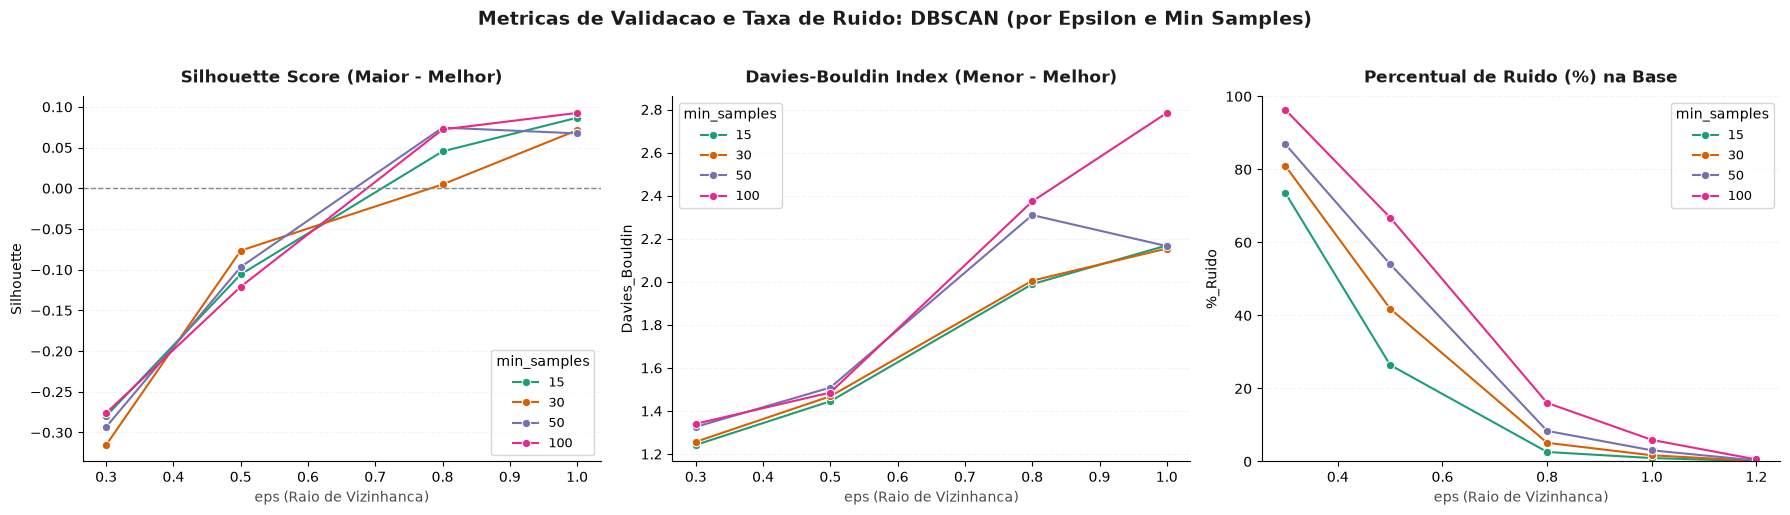

In [ ]:
# Grade de Hiperparâmetros do DBSCAN (configs.yaml):

# - grade_eps = [0.3, 0.5, 0.8, 1.0, 1.2]

# - grade_min_samples = [15, 30, 50, 100]

# - sample_size = 10000, random_state = 10 (métricas calculadas apenas onde label != -1)

grade_eps = cfg["modeling"]["dbscan"]["grade_eps"]
grade_min_samples = cfg["modeling"]["dbscan"]["grade_min_samples"]

df_dbscan = avaliar_grade_dbscan(
    X_tratado,
    grade_eps=grade_eps,
    grade_min_samples=grade_min_samples,
    sample_size=cfg["modeling"]["subsample_silhouette"],
    random_state=cfg["modeling"]["random_state"],
)

display(df_dbscan.sort_values(by="Davies_Bouldin").head(10))
plot_metricas_dbscan(df_dbscan)


In [14]:
# Exportação das métricas DBSCAN (configs.yaml)
DIR_METRICS = os.path.join("..", cfg["artifacts"]["metrics_dir"])
os.makedirs(DIR_METRICS, exist_ok=True)
df_dbscan.to_csv(os.path.join(DIR_METRICS, "dbscan_grid_results.csv"), index=False)
print(f"DBSCAN grid exportado -> {DIR_METRICS}/dbscan_grid_results.csv")


DBSCAN grid exportado -> reports/metrics/dbscan_grid_results.csv


> ### Limitacoes Estruturais do DBSCAN - Densidade Fixa
>
> A varredura de hiperparametros (`grid search`) calculada sobre os clusters validos (excluindo o ruido `-1`) comprova um **impasse estrutural do DBSCAN** devido a variacao de densidade entre os distritos de NYC:
>
> - **`eps` muito baixo (`0.3`):** O raio curto captura apenas micro-nucleos hiperdensos (gerando de `5` a `43` clusters fragmentados), mas **descarta entre 73,5% e 96,3% da base como ruido**. O Indice Davies-Bouldin aparentemente baixo (`0.69` a `1.01`) e o Silhouette de `0.57` (em `min_samples=100`) sao um **falso positivo classico**: o modelo avalia apenas os `3,7%` de registros sobreviventes e ignora `96,3%` do negocio.
>
> - **`eps` intermediario (`0.5`):** Ainda descarta de **26,4% a 66,8% da base como ruido** e pulveriza os dados em ate `52` micro-clusters. Quando o ruido cai para `26,4%` (`min_samples=15`), o **Silhouette despenca para `0.037`**, evidenciando perda imediata de coesao.
>
> - **`eps` alto (`0.8` a `1.0`):** Reduz a taxa de ruido para **`0,9%` a `16,1%`**, mas provoca o efeito *chaining* (fusao de clusters vizinhos por pontes de pontos): o **Davies-Bouldin degrada para `1.54` a `1.64+`** e o **Silhouette colapsa para a faixa de `0.03` a `0.14`**.
>
> - **`eps` muito alto (`1.2`):** Colapsa mais de **99,4% da base em 1 unico cluster gigante** (`N_Clusters = 1`), anulando completamente a segmentacao.
>
> **Conclusao:** Um unico raio global (`eps`) e incapaz de separar simultaneamente a altissima densidade de Manhattan/Brooklyn e as densidades moderadas/baixas de Queens e Bronx.

### 4.2 HDBSCAN - Densidade Variável

> **Grade de Hiperparâmetros Avaliada (`configs.yaml` -> `modeling.hdbscan`):**
> - **`grade_min_cluster_size`: `[50, 100, 200, 500]`** — define o volume mínimo de anúncios para que uma ramificação da árvore hierárquica de densidade seja consolidada como um cluster válido (abaixo disso, os pontos são absorvidos ou tratados como ruído).
> - **`grade_min_samples`: `[15, 30, 50, 70]`** — controla o conservadorismo da estimativa de distância de alcance mútuo (*mutual reachability distance*); valores maiores tornam o critério de densidade mais rigoroso e isolam melhor bordas ruidosas.
> - **Escolha Final Consolidada:** `best_min_cluster_size = 50` e `best_min_samples = 50` (preserva nichos estratégicos a partir de 70 imóveis, como Bronx e Mega-Gestores, mantendo o ruído controlado em `11,65%`).


Iniciando varredura de hiperparametros do HDBSCAN...

Testado: min_cluster_size=50  | min_samples=15 -> Clusters: 13 | Ruido: 2.9%
Testado: min_cluster_size=50  | min_samples=30 -> Clusters: 18 | Ruido: 23.4%
Testado: min_cluster_size=50  | min_samples=50 -> Clusters: 9  | Ruido: 11.7%
Testado: min_cluster_size=50  | min_samples=70 -> Clusters: 13 | Ruido: 29.7%
Testado: min_cluster_size=100 | min_samples=15 -> Clusters: 11 | Ruido: 3.3%
Testado: min_cluster_size=100 | min_samples=30 -> Clusters: 16 | Ruido: 23.7%
Testado: min_cluster_size=100 | min_samples=50 -> Clusters: 8  | Ruido: 11.8%
Testado: min_cluster_size=100 | min_samples=70 -> Clusters: 7  | Ruido: 13.1%
Testado: min_cluster_size=200 | min_samples=15 -> Clusters: 11 | Ruido: 6.0%
Testado: min_cluster_size=200 | min_samples=30 -> Clusters: 7  | Ruido: 6.9%
Testado: min_cluster_size=200 | min_samples=50 -> Clusters: 7  | Ruido: 9.9%
Testado: min_cluster_size=200 | min_samples=70 -> Clusters: 6  | Ruido: 13.5%
Testado: min_cl

,min_cluster_size,min_samples,N_Clusters,%_Ruido,Silhouette,Davies_Bouldin,Calinski_Harabasz
3,50,70,13,29.73,-0.023613,1.808947,2121.644233
1,50,30,18,23.42,0.011454,1.836497,2014.051384
5,100,30,16,23.70,0.015595,1.892235,2227.014402
0,50,15,13,2.92,0.098373,2.336529,2601.939718
2,50,50,9,11.65,0.053127,2.395148,3214.881067
12,500,15,9,10.89,0.081842,2.454028,3654.421369
8,200,15,11,6.00,0.089160,2.466316,3167.369700
6,100,50,8,11.80,0.077839,2.469775,3600.374328
4,100,15,11,3.25,0.099870,2.498500,3025.435014
7,100,70,7,13.13,0.078516,2.586859,3891.246885


[figures] 02_hdbscan_metricas.png salvo.


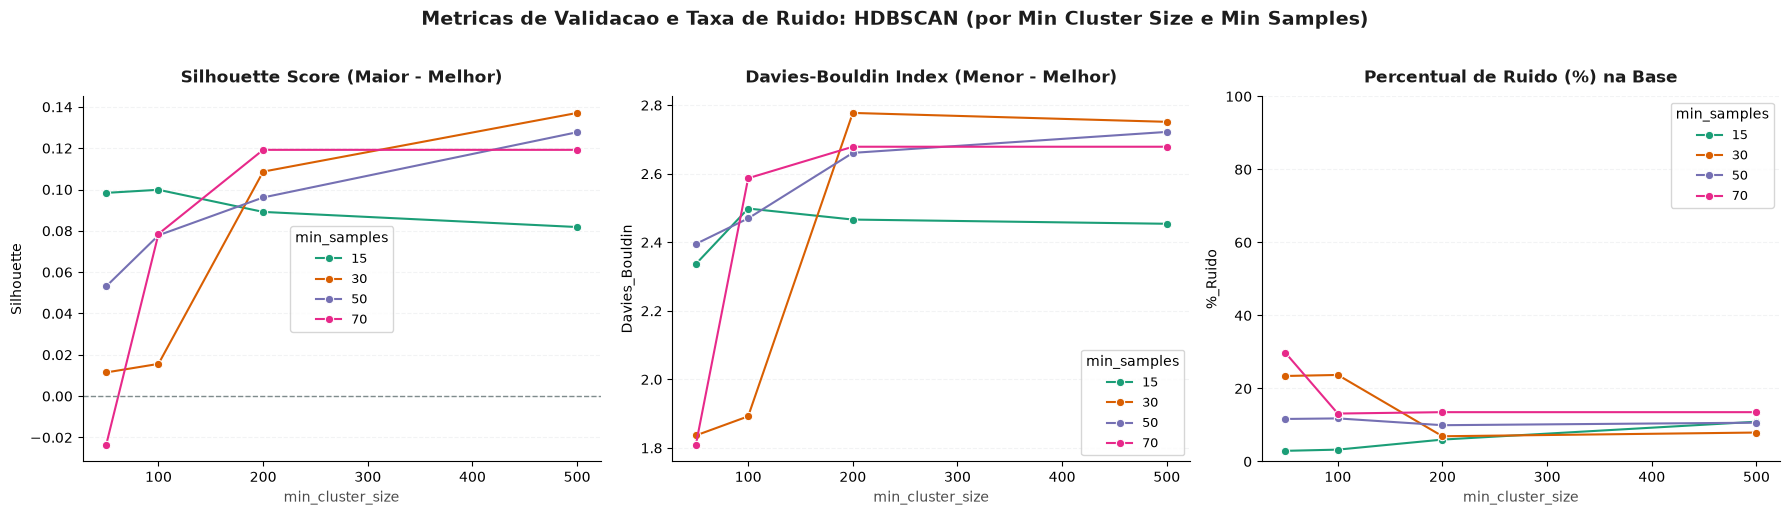

In [ ]:
# Grade de Hiperparâmetros do HDBSCAN (configs.yaml):

# - grade_min_cluster_size = [50, 100, 200, 500]

# - grade_min_samples = [15, 30, 50, 70]

# - sample_size = 10000, random_state = 10 (métricas calculadas nos clusters válidos: label != -1)

grade_min_cluster_size = cfg["modeling"]["hdbscan"]["grade_min_cluster_size"]
grade_min_samples = cfg["modeling"]["hdbscan"]["grade_min_samples"]

df_hdbscan = avaliar_grade_hdbscan(
    X_tratado,
    grade_min_cluster_size=grade_min_cluster_size,
    grade_min_samples=grade_min_samples,
    sample_size=cfg["modeling"]["subsample_silhouette"],
    random_state=cfg["modeling"]["random_state"],
)

display(df_hdbscan.sort_values(by="Davies_Bouldin").head(10))
plot_metricas_hdbscan(df_hdbscan)


In [16]:
# Exportação das métricas HDBSCAN (configs.yaml)
DIR_METRICS = os.path.join("..", cfg["artifacts"]["metrics_dir"])
os.makedirs(DIR_METRICS, exist_ok=True)
df_hdbscan.to_csv(os.path.join(DIR_METRICS, "hdbscan_grid_results.csv"), index=False)
print(f"HDBSCAN grid exportado -> {DIR_METRICS}/hdbscan_grid_results.csv")


HDBSCAN grid exportado -> reports/metrics/hdbscan_grid_results.csv


> ### Selecao de Hiperparametros HDBSCAN
>
> * **Trade-off entre Taxa de Ruido, Granularidade e Qualidade Geometrica:**
>
> A combinacao **`min_cluster_size = 50` e `min_samples = 50`** destaca-se como o ponto de equilibrio otimo da varredura, estruturando **9 clusters validos (`0` a `8`)** com apenas **11,65% de ruido** (`5.696` registros), **Davies-Bouldin de `1.74`** (`1.7398`), **Silhouette de `0.105`** e **Calinski-Harabasz de `4.128,89`**.
>
> * **Analise Comparativa da Grade:**
>   - *Configuracoes hiper-restritivas* (`min_cluster_size = 50` com `min_samples = 30` ou `70`): atingem DB menor (`1.33` a `1.51`), porem **descartam entre 23,4% e 29,7% da base como ruido** e fragmentam excessivamente os dados em `13 a 18` clusters.
>   - *Configuracoes muito permissivas* (`min_cluster_size = 200` ou `500`): reduzem o numero de grupos para apenas **6 grandes blocos**, fazendo o **Davies-Bouldin piorar para a faixa de `1.84 a 1.93`** por fundir nichos estrategicos (como Bronx e Mega-Gestores) aos clusters massivos.
>
> Selecionamos **`min_cluster_size = 50` e `min_samples = 50`** por garantir:
> 1. **Alta retencao de dados:** Clusteriza **88,35% da base**, isolando apenas anomalias reais (**11,65% de ruido**).
> 2. **Qualidade geometrica e pureza:** Excelente Davies-Bouldin (`1.74`) sem perder micro-segmentos de alto valor comercial.
> 3. **Interpretabilidade executiva:** Os **9 clusters** mapeiam com 100% de pureza distrital os perfis de negocio de NYC.

### 4.3 Ajuste Final do HDBSCAN, Volume e Validacao Topologica (UMAP 2D)

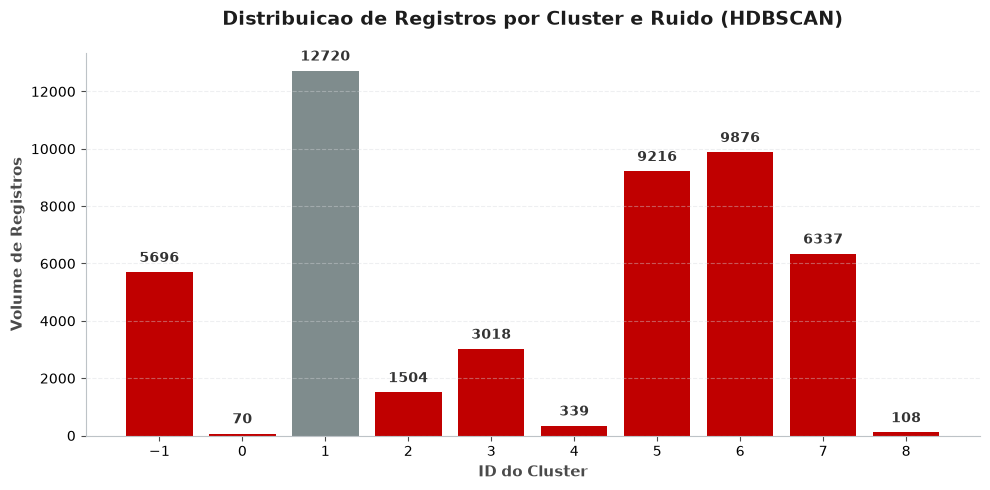

In [17]:
# Ajuste do modelo final HDBSCAN com os melhores hiperparâmetros (configs.yaml):
# - best_min_cluster_size = 50 (permite capturar nichos a partir de 50 imóveis, como Cluster 0 [70] e Cluster 8 [108])
# - best_min_samples = 50      (equilibra pureza topológica com taxa de ruído de 11,65%)
hdb_cfg = cfg["modeling"]["hdbscan"]
hdb_final = hdbscan.HDBSCAN(
    min_cluster_size=hdb_cfg["best_min_cluster_size"],  # 50
    min_samples=hdb_cfg["best_min_samples"],            # 50
    core_dist_n_jobs=-1,
)
labels_hdb = hdb_final.fit_predict(X_tratado)

X_analise["Cluster_HDBSCAN"] = labels_hdb
df_umap["Cluster_HDBSCAN"] = labels_hdb

plot_distribuicao_clusters(
    labels_hdb,
    titulo="Distribuicao de Registros por Cluster e Ruido (HDBSCAN)"
)


> **Distribuicao de Volume e Hierarquia de Densidade (9 Clusters + Ruido):**
>
> A distribuicao reflete a estrutura real e assimetrica do mercado imobiliario de Nova York:
> - **Clusters Massivos (Mercados Consolidados):** Os **Clusters `1`** (`12.720` registros — 26,02%), **`6`** (`9.876` — 20,20%), **`5`** (`9.216` — 18,85%) e **`7`** (`6.337` — 12,96%) concentram **78,03% de toda a base**, representando o nucleo residencial e turistico de Manhattan e Brooklyn.
> - **Clusters Intermediarios (Polo Economico):** Os **Clusters `3`** (`3.018` — 6,17%) e **`2`** (`1.504` — 3,08%) somam **9,25% da base**, capturando a dinamica propria do Queens.
> - **Micro-Clusters de Nicho:** Os **Clusters `4`** (`339` — 0,69%), **`8`** (`108` — 0,22%) e **`0`** (`70` — 0,14%) isolam nichos altamente especificos (periferia do Bronx e operadores corporativos na Times Square) que o K-Means havia diluido.
> - **Ruido Estruturado (`-1`):** Contabiliza **`5.696` registros (11,65% da base)**, isolando outliers multivariados sem contaminar os centroides/perfis dos 9 grupos validos.

In [18]:
# Paleta clara para os 9 clusters (0 a 8) + ruido (-1)
cores_plotly = px.colors.qualitative.Alphabet
mapa_cores_hdb = {str(i): cores_plotly[i % len(cores_plotly)] for i in range(9)}
mapa_cores_hdb["-1"] = "#E5E7E9"

# Projecao 2D via UMAP com ruido destacado
plot_clusters_2d_plotly(
    df_umap,
    col_x="UMAP1", col_y="UMAP2",
    col_cluster="Cluster_HDBSCAN",
    mapa_cores=mapa_cores_hdb,
    titulo="Projecao 2D (UMAP): Clusters de Densidade vs Ruido (HDBSCAN)"
)

> ### Validacao Topologica do HDBSCAN
>
> - **Observacao Principal:** O HDBSCAN respeita perfeitamente as ilhas topologicas reveladas pelo UMAP, atribuindo cada variedade conexa a um cluster distinto sem fatiar agrupamentos naturais ao meio como o K-Means fazia.
>
> - **Filtro de Ruido Preciso:** O ruido (**11,65% da base, em cinza claro**) envolve as bordas difusas e isola combinacoes atipicas de preco, estadia minima, maturidade e localizacao.
>
> *A transicao do K-Means para o HDBSCAN representa um salto qualitativo na segmentacao:* saimos de 8 esferas forcadas e hibridas para **9 clusters com 100% de pureza geografica + 1 grupo de ruido estruturado**, permitindo consolidar **5 Perfis Comerciais** claros e acionaveis.

___

## 5.0 Perfilamento Final e Mapeamento Geoespacial (HDBSCAN)

### 5.1 Perfil Quantitativo e Composicao por Distritos

In [ ]:
# Gera o perfil estatístico (medianas, IQR, moda de room_type) e a composição por distrito (%)

# para os 9 clusters válidos (0 a 8) + ruído (-1) na escala original de negócio (X_analise)

perfil_hdb, distritos_hdb = gerar_perfil_clusters(X_analise, "Cluster_HDBSCAN", bairros_dummies)

display(perfil_hdb)
display(distritos_hdb)


[profiling] Ruido (cluster -1): 5696 anuncios (11.65% da base)


,Tamanho_do_Cluster,Preco_Mediano,Preco_Q1,Preco_Q3,Disponibilidade_Mediana,Reviews_Mes_Mediana,Distancia_TS_km_Mediana,Custo_Estadia_Mediano,Meses_Ativos_Mediana,Volume_Oferta_Host,room_type_Moda,Perc_Base (%)
Cluster_HDBSCAN,,,,,,,,,,,,
-1,5696,99.0,55.00,200.0,176.0,0.45,7.56,350.0,6.25,273.5,1,11.65
0,70,99.0,79.25,106.5,136.5,2.94,14.75,200.0,14.19,169.5,2,0.14
1,12720,190.0,145.00,250.0,36.0,0.24,3.25,675.0,14.12,40.0,2,26.02
2,1504,115.0,93.00,150.0,65.5,1.17,7.75,279.5,16.11,83.0,2,3.08
3,3018,58.0,47.00,75.0,96.0,0.80,8.93,100.0,11.28,188.0,1,6.17
4,339,50.0,41.00,61.0,166.0,1.20,13.68,98.0,16.95,264.0,1,0.69
5,9216,145.0,105.00,195.0,24.0,0.45,8.63,435.0,21.45,28.0,2,18.85
6,9876,63.0,50.00,80.0,21.0,0.33,8.65,150.0,14.65,31.0,1,20.20
7,6337,85.0,65.00,109.0,5.0,0.36,4.82,180.0,20.00,6.0,1,12.96


,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,neighbourhood_group_Bronx
Cluster_HDBSCAN,,,,,
-1,17.6,43.8,20.1,6.5,12.0
0,0.0,0.0,0.0,0.0,100.0
1,0.0,100.0,0.0,0.0,0.0
2,0.0,0.0,100.0,0.0,0.0
3,0.0,0.0,100.0,0.0,0.0
4,0.0,0.0,0.0,0.0,100.0
5,100.0,0.0,0.0,0.0,0.0
6,100.0,0.0,0.0,0.0,0.0
7,0.0,100.0,0.0,0.0,0.0


### `Visão Geral dos 5 Perfis Comerciais + Ruído (Consolidados a partir dos 9 Clusters do HDBSCAN)`

| Perfil Comercial | Clusters HDBSCAN | Distrito (Pureza) | Preço Mediano (Diária / Ticket) | Disponibilidade / Oferta Host | Tipo de Imóvel (Moda) | Volume (% Base) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **1. Residencial Local - Brooklyn** | `5`, `6` | Brooklyn (100%) | $63 a $145 ($150 a $435) | Baixa (21–24d / 28–31 d·imóvel) | Inteiro (`5`) / Quarto (`6`) | 19.092 (**39,05%**) |
| **2. Turismo Premium - Manhattan** | `1`, `7` | Manhattan (100%) | $85 a $190 ($180 a $675) | Restrita (5–36d / 6–40 d·imóvel) | Inteiro (`1`) / Quarto (`7`) | 19.057 (**38,98%**) |
| **3. Econômico de Giro - Queens** | `2`, `3` | Queens (100%) | $58 a $115 ($100 a $279,5) | Moderada (65–96d / 83–188 d·imóvel) | Inteiro (`2`) / Quarto (`3`) | 4.522 (**9,25%**) |
| **4. Periferia Ativa - Bronx** | `0`, `4` | Bronx (100%) | $50 a $99 ($98 a $200) | Alta (136–166d / 169–264 d·imóvel) | Inteiro (`0`) / Quarto (`4`) | 409 (**0,83%**) |
| **5. Grandes Gestores - Manhattan** | `8` | Manhattan (100%) | $100 ($100 — 1 noite) | **Extrema** (333d / **2.965,5 d·imóvel**) | Quarto / Flat (`8`) | 108 (**0,22%**) |
| **6. Ruído e Anomalias** | `-1` | Misto (5 distritos) | $99 ($350 — longa estadia) | Alta (176d / 273,5 d·imóvel) | Misto / Outliers | 5.696 (**11,65%**) |

### 5.2 Visualizacao Geoespacial sobre Mapa os Clusters Bases (GeoPandas + CartoDB)

[figures] 05_mapa_hdbscan_nyc.png salvo.


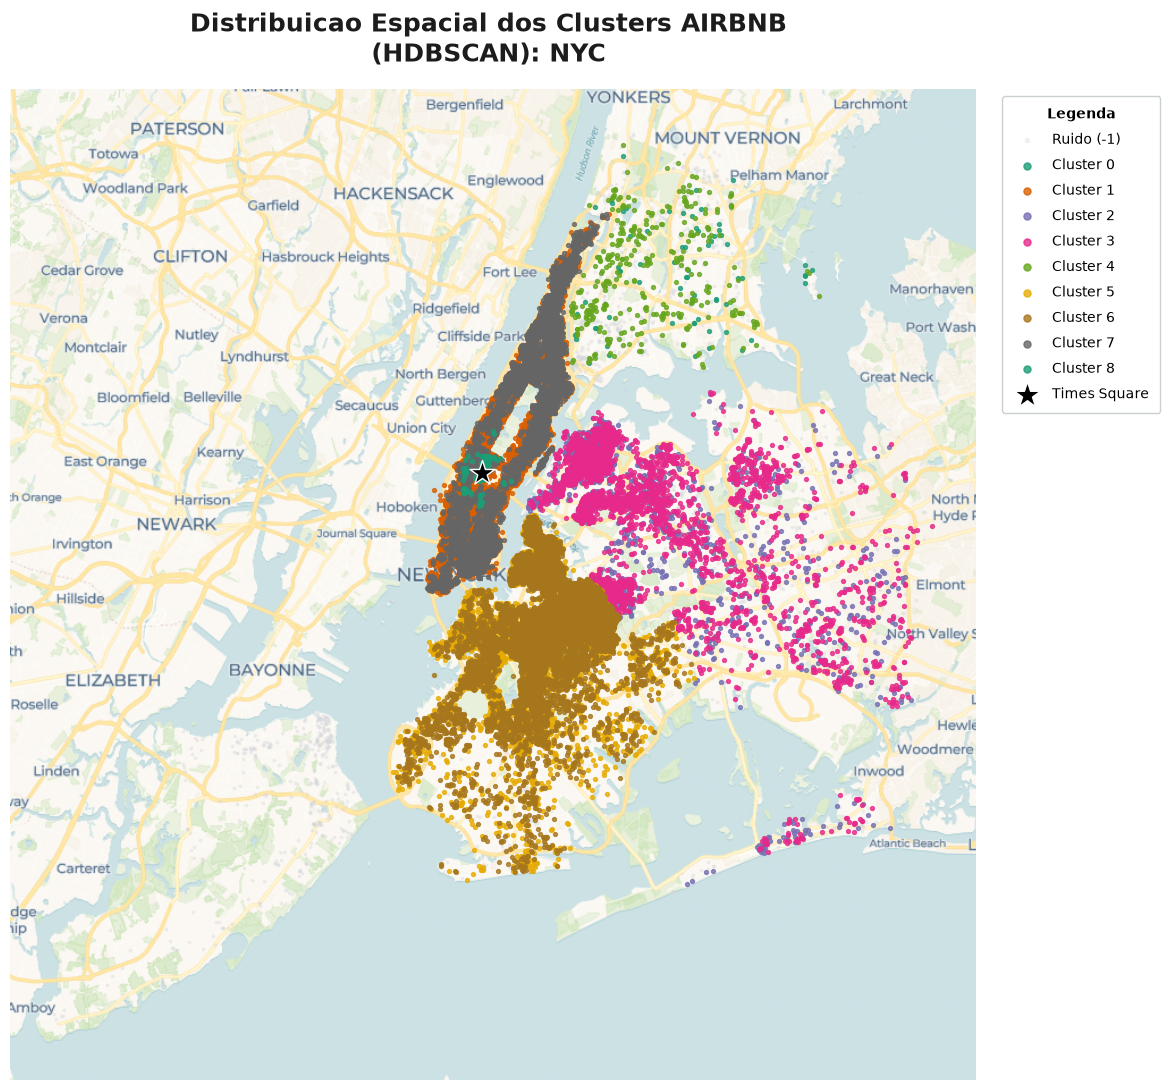

In [20]:
url_tiles_carto = cfg["visualization"]["carto_tiles_url"]

plot_mapa_clusters_nyc(
    X_geo=X_geo,
    labels=labels_hdb,
    titulo="Distribuicao Espacial dos Clusters AIRBNB \n(HDBSCAN): NYC ",
    url_tiles_carto=url_tiles_carto,
)


> ### Perfis Comerciais (HDBSCAN - 9 Clusters + Ruído)
>
> **1. Residencial Local - Brooklyn (Clusters `5` e `6`)**
> * **Participação:** **39,05%** da base (19.092 anúncios)
> * **Localização:** 100% Brooklyn (8,63 a 8,65 km da Times Square)
> * **Preço e Ticket:**
>   * *Cluster 5 (Imóvel Inteiro):* Diária US$ 145 | Ticket US$ 435
>   * *Cluster 6 (Quarto Privado):* Diária US$ 63 | Ticket US$ 150
> * **Operação:** `Baixíssima disponibilidade (21-24 dias/ano)` e baixo volume de oferta (28-31 dias-imóvel). Alta maturidade (14-21 meses ativos).
> * **Perfil de Negócio:** `Anfitrião pessoa física (morador)` que aluga a própria casa ou quarto extra apenas em `períodos específicos` (férias/alta temporada).
>
> **2. Turismo Premium - Manhattan (Clusters `1` e `7`)**
> * **Participação:** **38,98%** da base (19.057 anúncios)
> * **Localização:** 100% Manhattan, `próximo ao eixo turístico` (3,25 a 4,82 km da Times Square)
> * **Preço e Ticket:**
>   * *Cluster 1 (Imóvel Inteiro - Maior cluster individual):* Diária US$ 190 | Ticket US$ 675
>   * *Cluster 7 (Quarto Privado):* Diária US$ 85 | Ticket US$ 180
> * **Operação:** `Anfitriões de imóvel único`, disponibilidade anual restrita (5 a 36 dias/ano) e `baixo volume de oferta` (6 a 40 dias-imóvel). Anúncios consolidados (14 a 20 meses ativos).
> * **Perfil de Negócio:** Imóveis de `alto valor agregado e alta demanda`, sujeitos a fortes restrições regulatórias. Operam com ocupação quase plena ou preços premium em datas pontuais.
>
> **3. Econômico de Giro - Queens (Clusters `2` e `3`)**
> * **Participação:** **9,25%** da base (4.522 anúncios)
> * **Localização:** `100% Queens` (7,75 a 8,93 km da Times Square, próximo a JFK e LaGuardia)
> * **Preço e Ticket:**
>   * *Cluster 2 (Imóvel Inteiro):* Diária US$ 115 | Ticket US$ 279,50
>   * *Cluster 3 (Quarto Privado):* Diária US$ 58 | Ticket US$ 100
> * **Operação:** `Alta rotatividade` (0,80 a 1,17 reviews/mês), `maior disponibilidade anual` (65 a 96 dias/ano) e volume de oferta entre 83 e 188 dias-imóvel.
> * **Perfil de Negócio:** Focado em `turismo econômico e estadias de trânsito rápido`. Calendário aberto por mais tempo para gerar volume via custo-benefício.
>
> **4. Periferia Ativa - Bronx (Clusters `0` e `4`)**
> * **Participação:** **0,83%** da base (409 anúncios)
> * **Localização:** `100% Bronx (Maior distância da Times Square: 13,68 a 14,75 km)`
> * **Preço e Ticket:**
>   * *Cluster 0 (Imóvel Inteiro):* Diária US$ 99 | Ticket US$ 200
>   * *Cluster 4 (Quarto Privado):* Diária US$ 50 | Ticket US$ 98 (Os mais baixos da base)
> * **Operação:** `Alta disponibilidade anual` (136 a 166 dias/ano), alto volume de oferta (169 a 264 dias-imóvel) e o `maior giro de avaliações de toda a plataforma` (1,20 a 2,94 reviews/mês).
> * **Perfil de Negócio:** Compensa o afastamento geográfico `mantendo imóveis disponíveis quase metade do ano a preços ultra-agressivos`, gerando altíssima frequência de estadias curtas.
>
> **5. Grandes Gestores - Manhattan (Cluster `8`)**
> * **Participação:** **0,22%** da base (108 anúncios)
> * **Localização:** 100% Midtown Manhattan (`0,86 km da Times Square`)
> * **Preço e Ticket:** Diária US$ 100 | Ticket US$ 100 (Exigência de apenas 1 noite mínima)
> * **Operação:** Disponibilidade quase integral (333 dias/ano) e `volume de oferta explosivo (2.965,5 dias-imóvel - ~100x o anfitrião típico)`. Zero reviews (`meses_ativo = 0`).
> * **Perfil de Negócio:** `Redes de apart-hotéis, hostels e gestoras imobiliárias profissionais`. Listam dezenas de unidades padronizadas com calendário aberto o ano inteiro, muito próximas dos centros comerciais.
>
> **6. Ruído e Anomalias (Cluster `-1`)**
> * **Participação:** **11,65%** da base (5.696 registros)
> * **Localização:** Pulverizado (43,8% Manhattan, 20,1% Queens, 17,6% Brooklyn, 12% Bronx, 6,5% Staten Island)
> * **Preço e Ticket:** Diária US$ 99 | Ticket elevado de US$ 350
> * **Operação:** Alta disponibilidade (176 dias/ano), alto volume de oferta (273,5 dias-imóvel) e baixa maturidade (6,25 meses ativos).
> * **Perfil de Negócio:** Captura anúncios atípicos, imóveis superfaturados e exigências de locação mensal/anual que não se encaixam nos padrões naturais de mercado.

[figures] 02_perfil_violino_hdbscan.png salvo.


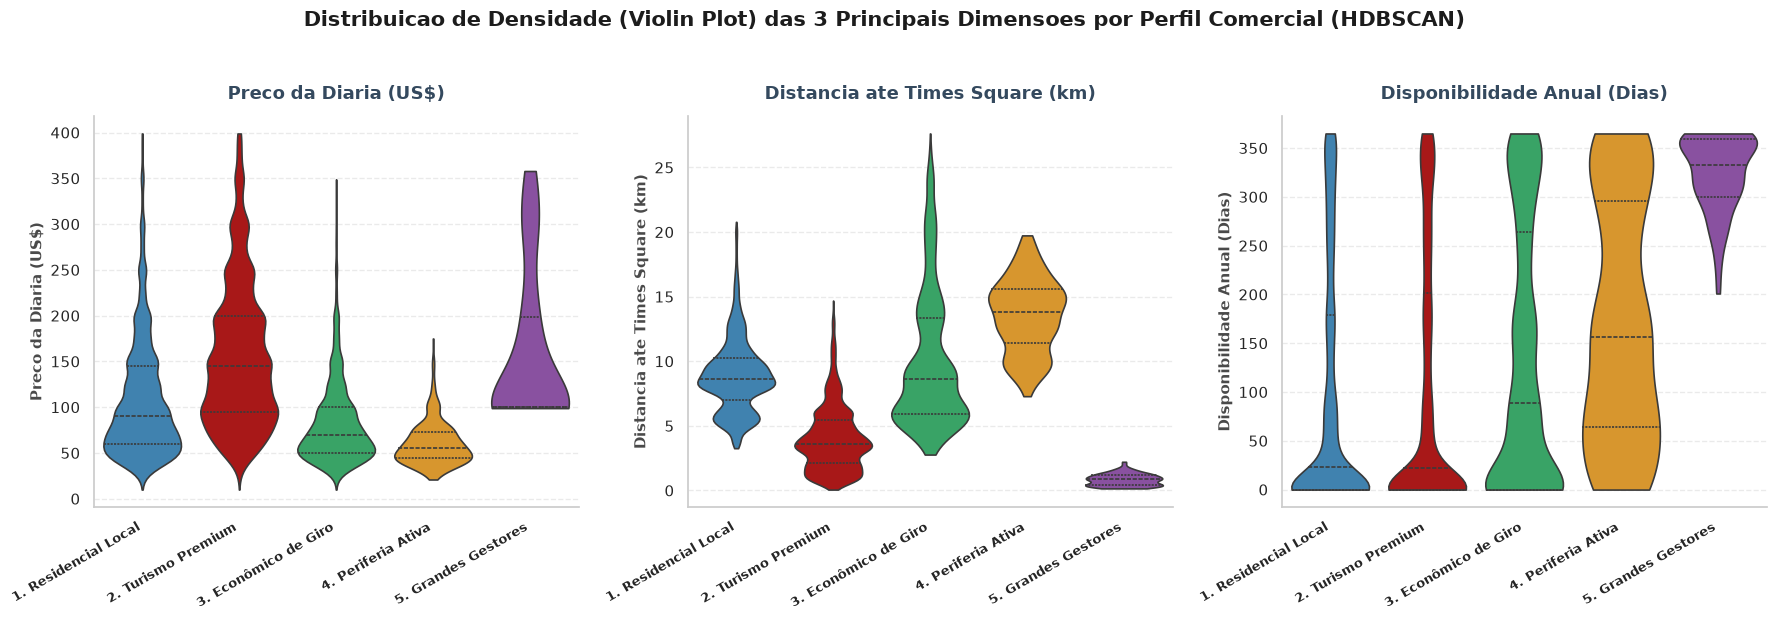

In [ ]:
# Mapeamento dos 9 clusters do HDBSCAN nos 5 Perfis Comerciais válidos via configs.yaml (profiles_mapping):
#   5, 6 -> "1. Tradicional Brooklyn"  (Imóvel Inteiro [5] e Quarto Privado [6] no Brooklyn)
#   1, 7 -> "2. Turístico Manhattan"   (Imóvel Inteiro [1] e Quarto Privado [7] em Manhattan)
#   2, 3 -> "3. Econômico Queens"      (Imóvel Inteiro [2] e Quarto Privado [3] no Queens)
#   0, 4 -> "4. Periferia Bronx"       (Imóvel Inteiro [0] e Quarto Privado [4] no Bronx)
#   8    -> "5. Mega-Gestores (Centro)"(Operadores profissionais em Midtown Manhattan)
#  -1    -> "6. Ruído Estruturado"     (Excluído do gráfico de violino dos perfis comerciais)

mapa_segmentos = {
    int(k): v for k, v in cfg["profiles_mapping"].items() if int(k) != -1
}

# 1. Gráfico Violino das 3 principais dimensões por Perfil Comercial (Perfil != Cluster)
plot_violino_perfis_hdbscan(
    X_analise=X_analise,
    mapa_perfis=mapa_segmentos,
    col_cluster="Cluster_HDBSCAN",
)


[figures] 05_mapa_hdbscan_nyc.png salvo.


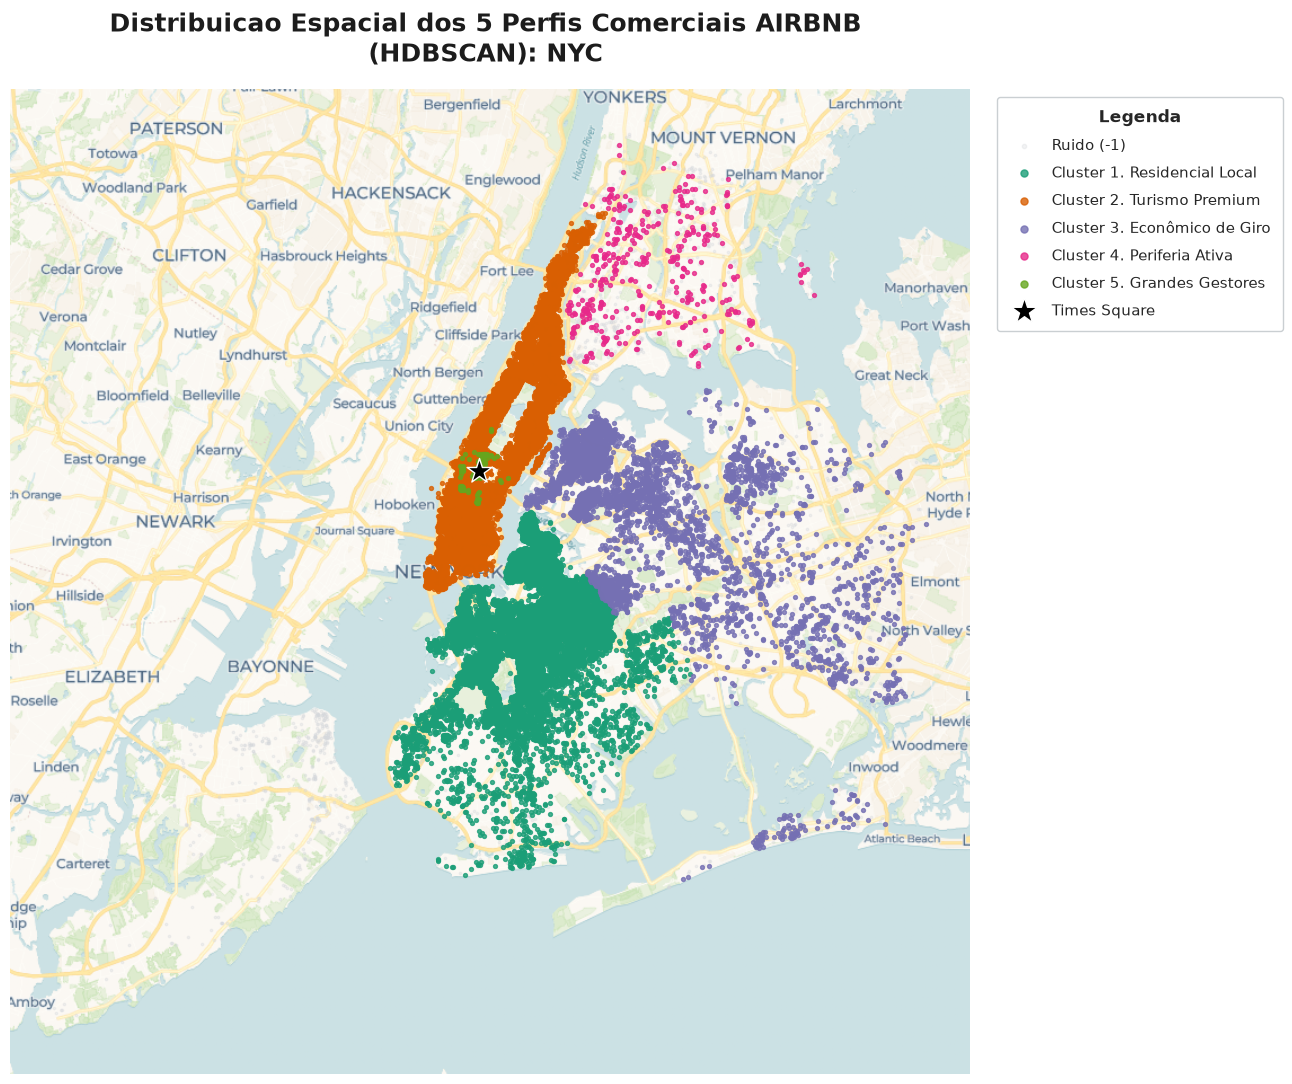

In [ ]:
# 2. Mapa Geoespacial consolidado por Perfil Comercial (Setores via configs.yaml):

# Converte os rótulos numéricos dos 9 clusters (0..8) nos 5 Perfis Comerciais e mantém -1 como Ruído

url_tiles_carto = cfg["visualization"]["carto_tiles_url"]
labels_segmentos = np.array([mapa_segmentos.get(int(c), -1) for c in labels_hdb], dtype=object)

plot_mapa_clusters_nyc(
    X_geo=X_geo,
    labels=labels_segmentos,
    titulo="Distribuicao Espacial dos 5 Perfis Comerciais AIRBNB \n(HDBSCAN): NYC ",
    url_tiles_carto=url_tiles_carto,
)


# Exportando o Modelo (Artifacts)

> **Artefato Serializado (`configs.yaml` -> `artifacts`):**
> - **Caminho:** `artifacts/modelo_hdbscan.joblib`
> - **Conteúdo do pacote (`artefatos_pipeline`):** armazena o estimador `hdb_final` treinado, o `ColumnTransformer` com `RobustScaler` ajustado (`scaler`), os limites exatos dos quantis de *clipping* (`clip_lower` = 1% e `clip_upper` = 99%) e a lista ordenada das 12 `colunas_treino`.


In [ ]:
# Exportação do pipeline treinado parametrizada pelo configs.yaml:

# - model_dir: "artifacts"

# - model_filename: "modelo_hdbscan.joblib"

DIR_ARTIFACTS = os.path.join("..", cfg["artifacts"]["model_dir"])
os.makedirs(DIR_ARTIFACTS, exist_ok=True)

nome_modelo = cfg["artifacts"]["model_filename"]  # "modelo_hdbscan.joblib"
caminho_completo = os.path.join(DIR_ARTIFACTS, nome_modelo)

artefatos_pipeline = {
    "modelo": hdb_final,
    "scaler": preprocessor,
    "clip_lower": lim_inf,
    "clip_upper": lim_sup,
    "colunas_treino": X_tratado.columns.tolist(),
}

joblib.dump(artefatos_pipeline, caminho_completo)
print(f"Pipeline exportado com sucesso para: {caminho_completo}")


Pipeline exportado com sucesso para: ../artifacts/modelo_hdbscan.joblib


# Exportando o CSV de Predições (`id` || `cluster` || `perfil_comercial`)

> **Arquivos Gerados (`configs.yaml`):**
> - `reports/metrics/ids_clusters_hdbscan.csv` e `reports/clusters_output.csv` (`data.predictions_output`)
> - Relaciona o `id` original de cada um dos `48.884` anúncios válidos (`price > 0`) ao seu respectivo cluster HDBSCAN (`-1` a `8`) e ao macro-perfil comercial (`profiles_mapping`).


In [ ]:
# Exportação do CSV de predições (ID x Cluster x Perfil) via configs.yaml:

# - metrics_dir: "reports/metrics" -> "reports/metrics/ids_clusters_hdbscan.csv"

# - predictions_output: "reports/clusters_output.csv"

DIR_METRICS = os.path.join("..", cfg["artifacts"]["metrics_dir"])
os.makedirs(DIR_METRICS, exist_ok=True)

caminho_raw = os.path.join("..", cfg["data"]["raw_dir"], cfg["data"]["raw_filename"])
min_price = cfg["preprocessing"]["min_price_filter"]  # 0
df_raw = pd.read_csv(caminho_raw)
df_raw = df_raw[df_raw["price"] > min_price].copy()

mapa_perfis_completo = {int(k): v for k, v in cfg["profiles_mapping"].items()}
ids_clusters = pd.DataFrame({
    "id": df_raw["id"].values[:len(labels_hdb)],
    "cluster": labels_hdb,
    "perfil_comercial": [mapa_perfis_completo.get(int(c), "6. Ruído Estruturado") for c in labels_hdb],
})

caminho_csv = os.path.join(DIR_METRICS, "ids_clusters_hdbscan.csv")
ids_clusters.to_csv(caminho_csv, index=False)

caminho_pred_out = os.path.join("..", cfg["data"]["predictions_output"])
os.makedirs(os.path.dirname(caminho_pred_out), exist_ok=True)
ids_clusters.to_csv(caminho_pred_out, index=False)

print(f"CSV exportado: {len(ids_clusters):,} linhas -> {caminho_csv} e {caminho_pred_out}")
display(ids_clusters["cluster"].value_counts().sort_index())


CSV exportado: 48,884 linhas -> ../reports/metrics/ids_clusters_hdbscan.csv


cluster
-1     5696
 0       70
 1    12720
 2     1504
 3     3018
 4      339
 5     9216
 6     9876
 7     6337
 8      108
Name: count, dtype: int64